# 3. Feature Engineering
Naye features banana (PPI), high-cardinality columns ko group karna (CPU, GPU, OS) aur kaam ke na hone wale columns hatana.

**Input:** `data/processed/02_preprocessed.csv`  
**Output:** `data/processed/03_features.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from common import PREPROCESSED_FILE, FEATURES_FILE, FEATURES, TARGET

In [2]:
df = pd.read_csv(PREPROCESSED_FILE)
print(df.shape)
df.head()

(1274, 17)


,Company,TypeName,Inches,Cpu,Ram,Gpu,OpSys,Weight,Price,TouchScreen,IPS,X_res,Y_res,HDD,SSD,Hybrid,Flash_Storage
0,Apple,Ultrabook,13.3,Intel Core i5 2.3GHz,8,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832,0,1,2560,1600,0,128,0,0
1,Apple,Ultrabook,13.3,Intel Core i5 1.8GHz,8,Intel HD Graphics 6000,macOS,1.34,47895.5232,0,0,1440,900,0,0,0,128
2,HP,Notebook,15.6,Intel Core i5 7200U 2.5GHz,8,Intel HD Graphics 620,No OS,1.86,30636.0000,0,0,1920,1080,0,256,0,0
3,Apple,Ultrabook,15.4,Intel Core i7 2.7GHz,16,AMD Radeon Pro 455,macOS,1.83,135195.3360,0,1,2880,1800,0,512,0,0
4,Apple,Ultrabook,13.3,Intel Core i5 3.1GHz,8,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080,0,1,2560,1600,0,256,0,0


## PPI (pixels per inch)
Screen size aur resolution alag-alag nahi, milkar sharpness batate hain.

In [3]:
df["PPI"] = (df["X_res"] ** 2 + df["Y_res"] ** 2) ** 0.5 / df["Inches"]
df[["Inches", "X_res", "Y_res", "PPI"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Inches,1274.0,15.022449,1.429940,10.100000,14.000000,15.600000,15.600000,18.400000
X_res,1274.0,1900.463108,493.312718,1366.000000,1920.000000,1920.000000,1920.000000,3840.000000
Y_res,1274.0,1074.144427,283.865869,768.000000,1080.000000,1080.000000,1080.000000,2160.000000
PPI,1274.0,147.019538,42.979971,90.583402,127.335675,141.211998,157.350512,352.465147


## CPU
`Intel Core i7 7500U 2.7GHz` jaisi 100+ unique values hain. Family level par group karte hain.

In [4]:
def cpu_group(cpu):
    if "Intel" in cpu:
        for family in ("Core i7", "Core i5", "Core i3"):
            if family in cpu:
                return f"Intel {family}"
        return "Intel Other"
    if "AMD" in cpu:
        return "AMD"
    return "Other"

df["CPU_name"] = df["Cpu"].apply(cpu_group)
df["CPU_name"].value_counts()

CPU_name
Intel Core i7    515
Intel Core i5    423
Intel Other      141
Intel Core i3    134
AMD               60
Other              1
Name: count, dtype: int64

## GPU
Sirf brand rakhte hain. `ARM` ki sirf 1 row hai, model use seekh nahi sakta, isliye hata dete hain.

In [5]:
df["Gpu_brand"] = df["Gpu"].str.split().str[0]
print(df["Gpu_brand"].value_counts())

df = df[df["Gpu_brand"] != "ARM"].reset_index(drop=True)

Gpu_brand
Intel     703
Nvidia    396
AMD       174
ARM         1
Name: count, dtype: int64


## Operating system
Windows / Mac / Other (Linux, No OS, Chrome OS, Android).

In [6]:
def os_group(os_name):
    if os_name.startswith("Windows"):
        return "Windows"
    if os_name in ("macOS", "Mac OS X"):
        return "Mac"
    return "Other"

df["OpSys"] = df["OpSys"].apply(os_group)
df["OpSys"].value_counts()

OpSys
Windows    1100
Other       152
Mac          21
Name: count, dtype: int64

## Correlation with price
`Hybrid` aur `Flash_Storage` ka price se almost koi relation nahi aur values bahut kam laptops mein hain, isliye drop.

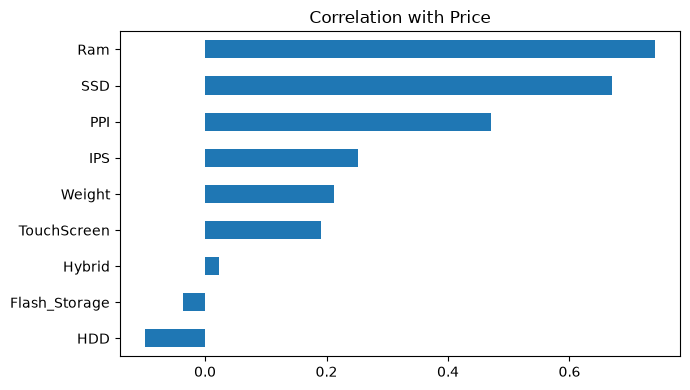

HDD             -0.098481
Flash_Storage   -0.036712
Hybrid           0.022490
TouchScreen      0.190382
Weight           0.211667
IPS              0.251514
PPI              0.471481
SSD              0.669808
Ram              0.739996
Name: Price, dtype: float64

In [7]:
numeric_cols = ["Ram", "Weight", "TouchScreen", "IPS", "PPI", "HDD", "SSD", "Hybrid", "Flash_Storage", TARGET]
corr = df[numeric_cols].corr()[TARGET].drop(TARGET).sort_values()

corr.plot(kind="barh", figsize=(7, 4), title="Correlation with Price")
plt.tight_layout()
plt.show()
corr

In [8]:
df = df.drop(columns=["Inches", "X_res", "Y_res", "Cpu", "Gpu", "Hybrid", "Flash_Storage"])

# Keep only the columns the model will use (+ target), in a fixed order
df = df[FEATURES + [TARGET]]
assert df.isna().sum().sum() == 0
df.head()

,Company,TypeName,OpSys,CPU_name,Gpu_brand,Ram,Weight,TouchScreen,IPS,PPI,HDD,SSD,Price
0,Apple,Ultrabook,Mac,Intel Core i5,Intel,8,1.37,0,1,226.983005,0,128,71378.6832
1,Apple,Ultrabook,Mac,Intel Core i5,Intel,8,1.34,0,0,127.677940,0,0,47895.5232
2,HP,Notebook,Other,Intel Core i5,Intel,8,1.86,0,0,141.211998,0,256,30636.0000
3,Apple,Ultrabook,Mac,Intel Core i7,AMD,16,1.83,0,1,220.534624,0,512,135195.3360
4,Apple,Ultrabook,Mac,Intel Core i5,Intel,8,1.37,0,1,226.983005,0,256,96095.8080


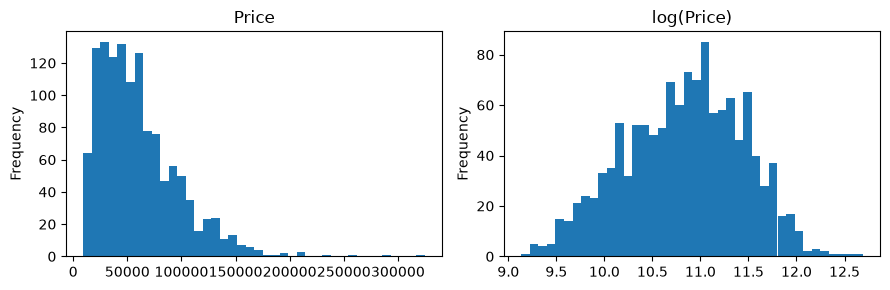

In [9]:
# Price is right-skewed -> the model is trained on log(Price)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
df[TARGET].plot(kind="hist", bins=40, ax=axes[0], title="Price")
np.log(df[TARGET]).plot(kind="hist", bins=40, ax=axes[1], title="log(Price)")
plt.tight_layout()
plt.show()

In [10]:
df.to_csv(FEATURES_FILE, index=False)
print("Saved:", FEATURES_FILE.name, df.shape)

Saved: 03_features.csv (1273, 13)
